In [1]:
%pip install -q torch numpy matplotlib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import re
import unicodedata
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset

SEED = 0
URL = 'https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt'
PLIK = Path('lalka-tom-pierwszy.txt')   
PROPORCJE = (0.8, 0.1, 0.1)             
NAZWY = ('trening', 'walidacja', 'test')
BATCH = 32
SEKW_GLOWNE = 40                        
SEKWY = [10, 20, 40, 80, 160, 320]      
UNK_SYM = '�'                     
OUT = Path('rysunki')
OUT.mkdir(exist_ok=True)

np.random.seed(SEED)
torch.manual_seed(SEED)
W = {}  

KOLOR = {'trening': '#2a78d6', 'walidacja': '#eb6834', 'test': '#1baf7a'}
ATRAMENT, ATRAMENT2, SIATKA, TLO = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': TLO, 'axes.facecolor': TLO, 'savefig.facecolor': TLO,
    'text.color': ATRAMENT, 'axes.labelcolor': ATRAMENT2,
    'xtick.color': ATRAMENT2, 'ytick.color': ATRAMENT2,
    'axes.edgecolor': SIATKA, 'font.size': 11,
})


def styl(ax):
    """Zdejmuje zbędne ramki i ustawia delikatną siatkę."""
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color=SIATKA, linewidth=1)
    ax.set_axisbelow(True)

In [3]:
if not PLIK.exists():
    PLIK.write_bytes(urllib.request.urlopen(URL).read())
surowy = PLIK.read_bytes().decode('utf-8')
print('Długość surowego tekstu:', len(surowy), 'znaków')
print('--- początek ---')
print(repr(surowy[:400]))
print('--- koniec ---')
print(repr(surowy[-900:]))

Długość surowego tekstu: 784082 znaków
--- początek ---
'Bolesław Prus\r\n\r\nLalka\r\n\r\nISBN 978-83-288-2673-1\r\n\r\n\r\n\r\n\r\n\r\nTom I\r\n\r\n\r\n\r\nI. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?\r\n\r\nW początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorąco interesowała się przys'
--- koniec ---
'cencji Wolnej Sztuki 1.3: https://artlibre.org/licence/lal/pl/\r\nFundacja Wolne Lektury zastrzega sobie prawa do wydania krytycznego zgodnie z art. Art.99(2) Ustawy o prawach autorskich i prawach pokrewnych.\r\nWykorzystując zasoby z Wolnych Lektur, należy pamiętać o zapisach licencji oraz zasadach, które spisaliśmy w Zasadach wykorzystania Wolnych Lektur: https://wolnelektury.pl/info/zasady-wykorzystania/\r\nZapoznaj się z nimi, zanim udostępnisz dalej nasze książki.\r\n\r\nTekst opraco

In [4]:
STOPKA = 'Ta lektura, podobnie jak tysiące innych'   


def oczysc(tekst):
    """Czyści tekst z Wolnych Lektur; zwraca (tekst, słownik z licznikami zmian)."""
    log = {'znaków_przed': len(tekst)}
    t = unicodedata.normalize('NFC', tekst)          
    log['zmieniono_przez_NFC'] = t != tekst
    t = t.replace('\r\n', '\n').replace('\r', '\n')  
    i = t.find(STOPKA)
    if i == -1:                                      
        i = t.rfind('\n-----')
    if i != -1:                                    
        log['usunieto_stopke_znakow'] = len(t) - i
        t = t[:i]
    t, log['znaczniki_html'] = re.subn(r'<[^>]+>', '', t)
    t, log['wielokrotne_spacje_tabulatory'] = re.subn(r'[ \t]+', ' ', t)
    t = re.sub(r' ?\n ?', '\n', t)                    
    t, log['nadmiarowe_puste_linie'] = re.subn(r'\n{3,}', '\n\n', t)
    t = t.strip(' \n-') + '\n'
    log['znaków_po'] = len(t)
    return t, log


tekst, log_czyszczenia = oczysc(surowy)
W['czyszczenie'] = log_czyszczenia
for k, v in log_czyszczenia.items():
    print(f'{k:32s} {v}')

assert UNK_SYM not in tekst
assert not any(c in tekst for c in 'ÃÄÅ'), 'podejrzenie błędnego kodowania (mojibake)'
pl = 'ąćęłńóśźżĄĆĘŁŃÓŚŹŻ'
print('\nPolskie znaki w tekście:', {c: tekst.count(c) for c in pl if c in tekst})
print('\n--- fragment po oczyszczeniu (początek) ---')
print(tekst[:600])
print('--- fragment po oczyszczeniu (środek) ---')
sr = len(tekst) // 2
print(tekst[sr:sr + 500])
print('--- koniec po oczyszczeniu ---')
print(repr(tekst[-300:]))

znaków_przed                     784082
zmieniono_przez_NFC              False
usunieto_stopke_znakow           1526
znaczniki_html                   0
wielokrotne_spacje_tabulatory    117800
nadmiarowe_puste_linie           37
znaków_po                        772633

Polskie znaki w tekście: {'ą': 7308, 'ć': 3069, 'ę': 10281, 'ł': 16129, 'ń': 741, 'ó': 4971, 'ś': 4769, 'ź': 429, 'ż': 6503, 'Ł': 191, 'Ó': 2, 'Ś': 41, 'Ź': 4, 'Ż': 183}

--- fragment po oczyszczeniu (początek) ---
Bolesław Prus

Lalka

ISBN 978-83-288-2673-1

Tom I

I. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?

W początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorąco interesowała się przyszłością galanteryjnego sklepu pod firmą J. Mincel i S. Wokulski.

W renomowanej jadłodajni, gdzie na wieczorną przekąskę zbierali się właś

In [5]:
def granice(t, prop):
    """Indeksy początków fragmentów [0, c1, c2, len(t)] z przesunięciem na początek akapitu."""
    n, cuts, acc = len(t), [0], 0.0
    for p in prop[:-1]:
        acc += p
        c = int(round(n * acc))
        j = t.find('\n\n', c)
        cuts.append(j + 2 if j != -1 else c)
    cuts.append(n)
    assert all(a < b for a, b in zip(cuts, cuts[1:])), cuts
    return cuts


cuts = granice(tekst, PROPORCJE)
czesci = {nazwa: tekst[a:b] for nazwa, a, b in zip(NAZWY, cuts, cuts[1:])}
assert ''.join(czesci.values()) == tekst        
W['granice'] = cuts
for nazwa, c in czesci.items():
    print(f'{nazwa:10s} znaków: {len(c):7d}  ({len(c) / len(tekst):6.2%})  '
          f'początek: {c[:50]!r}')

trening    znaków:  618151  (80.01%)  początek: 'Bolesław Prus\n\nLalka\n\nISBN 978-83-288-2673-1\n\nTom '
walidacja  znaków:   77475  (10.03%)  początek: '— Nic o tym nie wiem — odpowiedział Szlangbaum spu'
test       znaków:   77007  ( 9.97%)  początek: '— Szpigelman?… Ach, prawda!… Zapomniałam o nim. Po'


In [6]:
znaki_tren = sorted(set(czesci['trening']))
znaki = [UNK_SYM] + znaki_tren
stoi = {z: i for i, z in enumerate(znaki)}
itos = {i: z for z, i in stoi.items()}
V = len(znaki)
UNK_ID = stoi[UNK_SYM]


def enc(s):
    """Tekst -> lista ID; znaki spoza słownika dostają UNK_ID."""
    return [stoi.get(c, UNK_ID) for c in s]


def dec(ids):
    """Lista ID -> tekst."""
    return ''.join(itos[int(i)] for i in ids)


def z_unk(s):
    """Tekst tak, jak powinien wyglądać po kodowaniu i dekodowaniu (OOV -> UNK_SYM)."""
    return ''.join(c if c in stoi else UNK_SYM for c in s)


print('Rozmiar słownika V =', V, f'(w tym 1 ID na UNK; {V - 1} znaków z treningu)')
print('Znaki:', repr(''.join(znaki_tren)))

dane = {n: np.array(enc(c), dtype=np.int64) for n, c in czesci.items()}
zrodlo = {n: z_unk(c) for n, c in czesci.items()}       

W['slownik'] = {'V': V, 'znaki_treningu': ''.join(znaki_tren)}
W['oov'] = {}
W['kodowanie'] = {}
for n, c in czesci.items():
    oov = Counter(ch for ch in c if ch not in stoi)
    W['oov'][n] = {'wystapien': sum(oov.values()), 'znaki': dict(oov)}
    ok = dec(dane[n]) == zrodlo[n]
    ok_dokladnie = dec(dane[n]) == c                    
    W['kodowanie'][n] = {'dekodowanie_zgodne_z_zrodlem_po_UNK': ok,
                         'dekodowanie_identyczne_z_oryginalem': ok_dokladnie}
    print(f'{n:10s} znaków spoza słownika: {sum(oov.values()):4d}  {dict(oov)}  '
          f'| dec(enc)=zrodlo: {ok}  | identyczne z oryginałem: {ok_dokladnie}')
    assert ok

for n, c in czesci.items():
    frag = c[:1000]
    if all(ch in stoi for ch in frag):
        assert dec(enc(frag)) == frag
print('Test dokładnego odtworzenia pierwszych 1000 znaków każdej części: OK')

Rozmiar słownika V = 102 (w tym 1 ID na UNK; 101 znaków z treningu)
Znaki: "\n !'()*,-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz«»ÓàçéóöüąćęŁłńŚśŹźŻż–—”„…"
trening    znaków spoza słownika:    0  {}  | dec(enc)=zrodlo: True  | identyczne z oryginałem: True
walidacja  znaków spoza słownika:    0  {}  | dec(enc)=zrodlo: True  | identyczne z oryginałem: True
test       znaków spoza słownika:    0  {}  | dec(enc)=zrodlo: True  | identyczne z oryginałem: True
Test dokładnego odtworzenia pierwszych 1000 znaków każdej części: OK


In [7]:
class DatasetZnakowy(Dataset):
    """Pary (wejście, cel) z jednego fragmentu tekstu; cel = wejście przesunięte o 1 znak."""

    def __init__(self, ids, sekw):
        self.ids = ids
        self.sekw = sekw

    def __len__(self):
        return max(0, len(self.ids) - self.sekw)

    def __getitem__(self, i):
        if not 0 <= i < len(self):
            raise IndexError(i)
        x = self.ids[i:i + self.sekw]
        y = self.ids[i + 1:i + self.sekw + 1]            
        return torch.from_numpy(x), torch.from_numpy(y)


def zrob_loader(ds, trening):
    """Trening: tasowanie i drop_last; walidacja/test: kolejność oryginalna, wszystkie pary."""
    gen = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=BATCH, shuffle=trening, drop_last=trening,
                      generator=gen if trening else None)


def oczekiwane(n_znakow, sekw, trening):
    """Liczba par i batchy wyliczona ze wzoru (kontrola klasy Dataset i DataLoader)."""
    pary = max(0, n_znakow - sekw)
    return pary, (pary // BATCH if trening else -(-pary // BATCH))


ds = {n: DatasetZnakowy(dane[n], SEKW_GLOWNE) for n in NAZWY}
dl = {n: zrob_loader(ds[n], n == 'trening') for n in NAZWY}

W['tabela'] = []
print(f'SEKW = {SEKW_GLOWNE}, batch_size = {BATCH}\n')
print(f'{"zbiór":10s}{"dok.":>5s}{"znaków":>9s}{"% korpusu":>11s}{"różnych zn.":>13s}'
      f'{"par":>9s}{"batchy":>8s}  loader')
for n in NAZWY:
    par, bat = oczekiwane(len(dane[n]), SEKW_GLOWNE, n == 'trening')
    assert len(ds[n]) == par and len(dl[n]) == bat
    wiersz = {'zbior': n, 'dokumentow': 1, 'znakow': len(dane[n]),
              'udzial': len(dane[n]) / len(tekst), 'rozne_znaki': len(set(czesci[n])),
              'par': par, 'batchy': bat,
              'drop_last': n == 'trening', 'shuffle': n == 'trening'}
    W['tabela'].append(wiersz)
    print(f'{n:10s}{1:5d}{wiersz["znakow"]:9d}{wiersz["udzial"]:11.2%}{wiersz["rozne_znaki"]:13d}'
          f'{par:9d}{bat:8d}  shuffle={wiersz["shuffle"]}, drop_last={wiersz["drop_last"]}')

SEKW = 40, batch_size = 32

zbiór      dok.   znaków  % korpusu  różnych zn.      par  batchy  loader
trening       1   618151     80.01%          101   618111   19315  shuffle=True, drop_last=True
walidacja     1    77475     10.03%           74    77435    2420  shuffle=False, drop_last=False
test          1    77007      9.97%           81    76967    2406  shuffle=False, drop_last=False


In [8]:
def wszystkie_wystapienia(s, wzor):
    """Wszystkie pozycje, w których `wzor` występuje w `s`."""
    poz, p = [], s.find(wzor)
    while p != -1:
        poz.append(p)
        p = s.find(wzor, p + 1)
    return poz


W['kontrola'] = {}
for n in NAZWY:
    xb, yb = next(iter(dl[n]))
    B = xb.shape[0]
    assert tuple(xb.shape) == tuple(yb.shape) == (B, SEKW_GLOWNE)
    assert xb.dtype == torch.int64 and yb.dtype == torch.int64
    zakres = (min(xb.min().item(), yb.min().item()), max(xb.max().item(), yb.max().item()))
    assert zakres[0] >= 0 and zakres[1] < V

    x_txt, y_txt = dec(xb[0].tolist()), dec(yb[0].tolist())
    assert x_txt[1:] == y_txt[:-1]                     
    poz = [p for p in wszystkie_wystapienia(zrodlo[n], x_txt)
           if zrodlo[n][p + 1:p + SEKW_GLOWNE + 1] == y_txt]
    assert poz, 'par z batcha nie znaleziono w tekście źródłowym'
    p = poz[0]
    assert zrodlo[n][p + SEKW_GLOWNE] == y_txt[-1]       
    i0 = len(ds[n]) // 2
    x0, y0 = ds[n][i0]
    assert dec(x0) == zrodlo[n][i0:i0 + SEKW_GLOWNE]
    assert dec(y0) == zrodlo[n][i0 + 1:i0 + SEKW_GLOWNE + 1]
    W['kontrola'][n] = {'ksztalt_X': list(xb.shape), 'ksztalt_Y': list(yb.shape),
                        'dtype': str(xb.dtype), 'zakres_ID': list(zakres),
                        'pozycja_w_czesci': p, 'wejscie': x_txt, 'cel': y_txt,
                        'indeks_znany': i0, 'wejscie_znane': dec(x0), 'cel_znany': dec(y0)}
    print(f'=== {n}: X {tuple(xb.shape)}, Y {tuple(yb.shape)}, dtype {xb.dtype}, '
          f'zakres ID {zakres[0]}..{zakres[1]} (V = {V})')
    print('  wejście :', repr(x_txt))
    print('  cel     :', repr(y_txt))
    print(f'  pozycja w części „{n}”: {p} (liczba trafień: {len(poz)}); '
          f'ostatni znak celu {y_txt[-1]!r} == znak źródła {zrodlo[n][p + SEKW_GLOWNE]!r}')
    print(f'  para nr {i0} z Dataset: {dec(x0)!r} -> {dec(y0)!r}')

=== trening: X (32, 40), Y (32, 40), dtype torch.int64, zakres ID 1..101 (V = 102)
  wejście : ' już z jakiej racji, dodał:\n\n— Jak te ka'
  cel     : 'już z jakiej racji, dodał:\n\n— Jak te kan'
  pozycja w części „trening”: 321374 (liczba trafień: 1); ostatni znak celu 'n' == znak źródła 'n'
  para nr 309055 z Dataset: 'żkę, potem lewą nóżkę, potem wystawia rą' -> 'kę, potem lewą nóżkę, potem wystawia rąc'
=== walidacja: X (32, 40), Y (32, 40), dtype torch.int64, zakres ID 2..98 (V = 102)
  wejście : '— Nic o tym nie wiem — odpowiedział Szla'
  cel     : ' Nic o tym nie wiem — odpowiedział Szlan'
  pozycja w części „walidacja”: 0 (liczba trafień: 1); ostatni znak celu 'n' == znak źródła 'n'
  para nr 38717 z Dataset: 'iedemdziesiąt jeden tysięcy. On dziś wię' -> 'edemdziesiąt jeden tysięcy. On dziś więc'
=== test: X (32, 40), Y (32, 40), dtype torch.int64, zakres ID 2..101 (V = 102)
  wejście : '— Szpigelman?… Ach, prawda!… Zapomniałam'
  cel     : ' Szpigelman?… Ach, prawda!… Zapom

 SEKW |        trening        |       walidacja       |         test         
      |       pary     batche |       pary     batche |       pary     batche
   10 |     618141      19316 |      77465       2421 |      76997       2407
   20 |     618131      19316 |      77455       2421 |      76987       2406
   40 |     618111      19315 |      77435       2420 |      76967       2406
   80 |     618071      19314 |      77395       2419 |      76927       2404
  160 |     617991      19312 |      77315       2417 |      76847       2402
  320 |     617831      19307 |      77155       2412 |      76687       2397


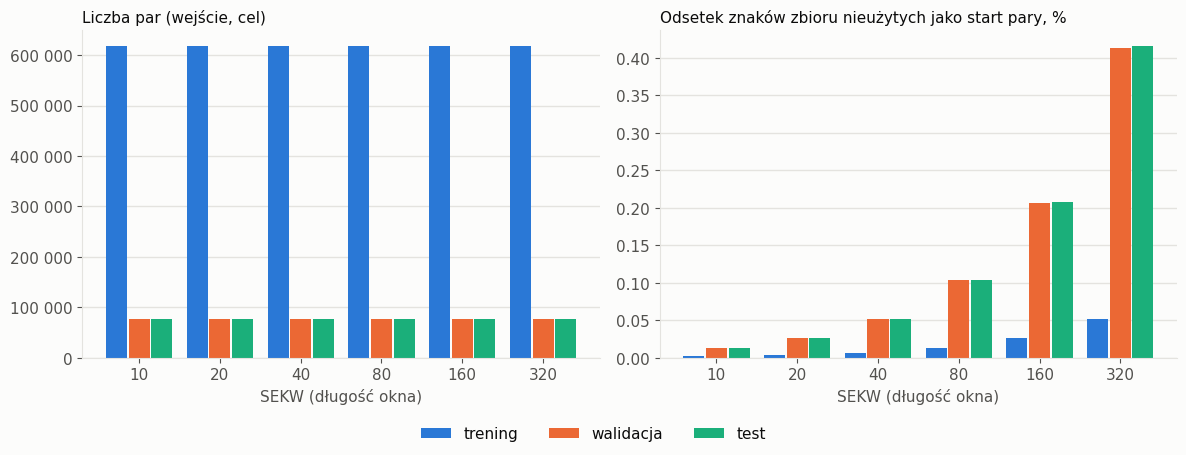

In [9]:
W['sekw'] = []
print(f'{"SEKW":>5s} | ' + ' | '.join(f'{n:^21s}' for n in NAZWY))
print(f'{"":>5s} | ' + ' | '.join(f'{"pary":>10s}{"batche":>11s}' for _ in NAZWY))
for s in SEKWY:
    wiersz = {'sekw': s}
    teksty = []
    for n in NAZWY:
        par, bat = oczekiwane(len(dane[n]), s, n == 'trening')
        d = DatasetZnakowy(dane[n], s)
        assert len(d) == par                                   
        wiersz[n] = {'par': par, 'batchy': bat,
                     'tracone_proc': 100 * s / len(dane[n])}
        teksty.append(f'{par:10d}{bat:11d}')
    W['sekw'].append(wiersz)
    print(f'{s:5d} | ' + ' | '.join(teksty))

x = np.arange(len(SEKWY))
szer = 0.26
fig, osie = plt.subplots(1, 2, figsize=(12, 4.6))
tytuly = ['Liczba par (wejście, cel)', 'Odsetek znaków zbioru nieużytych jako start pary, %']
klucze = ['par', 'tracone_proc']
for ax, tytul, klucz in zip(osie, tytuly, klucze):
    for k, n in enumerate(NAZWY):
        wart = [w[n][klucz] for w in W['sekw']]
        ax.bar(x + (k - 1) * (szer + 0.02), wart, szer, color=KOLOR[n], label=n)
    ax.set_xticks(x)
    ax.set_xticklabels(SEKWY)
    ax.set_xlabel('SEKW (długość okna)')
    ax.set_title(tytul, loc='left', fontsize=11, color=ATRAMENT)
    styl(ax)
osie[0].yaxis.set_major_formatter(lambda v, _: f'{v:,.0f}'.replace(',', ' '))
uchwyty, opisy = osie[0].get_legend_handles_labels()
fig.legend(uchwyty, opisy, loc='lower center', ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(OUT / 'pary_vs_sekw.png', dpi=150)
plt.show()

'␣'       93892  15.19%
'a'       44134   7.14%
'i'       42211   6.83%
'e'       37055   5.99%
'o'       34046   5.51%
'z'       27753   4.49%
'n'       24709   4.00%
's'       20503   3.32%
'r'       19291   3.12%
'y'       18477   2.99%
'c'       18331   2.97%
'w'       17756   2.87%
'k'       16790   2.72%
't'       16102   2.60%
'd'       15481   2.50%
'm'       14983   2.42%
'p'       13778   2.23%
'ł'       13186   2.13%
'u'       11579   1.87%
'l'       10918   1.77%


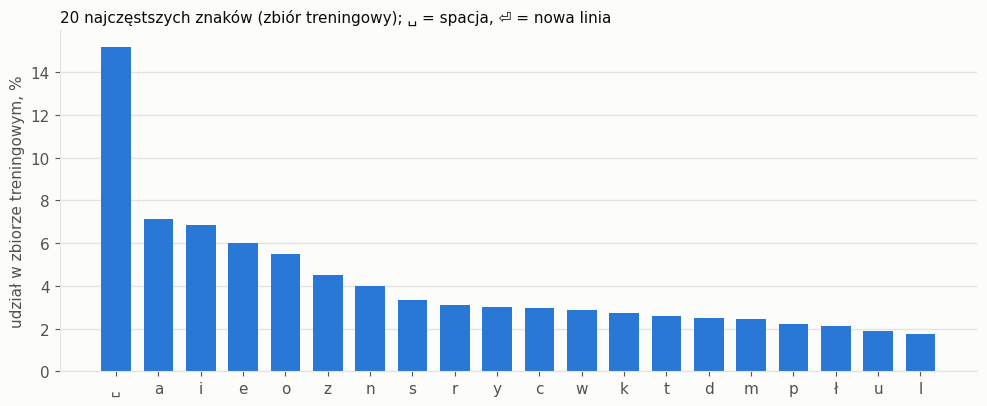

In [10]:
def etykieta(c):
    """Czytelna etykieta znaku (spacja i nowa linia mają własne symbole)."""
    return {' ': '␣', '\n': '⏎'}.get(c, c)


licz = Counter(czesci['trening'])
top = licz.most_common(20)
W['top_znaki'] = [{'znak': c, 'liczba': k, 'udzial': k / len(czesci['trening'])} for c, k in top]
for c, k in top:
    print(f'{etykieta(c)!r:6s} {k:8d}  {k / len(czesci["trening"]):6.2%}')

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar([etykieta(c) for c, _ in top], [100 * k / len(czesci['trening']) for _, k in top],
       color=KOLOR['trening'], width=0.7)
ax.set_ylabel('udział w zbiorze treningowym, %')
ax.set_title('20 najczęstszych znaków (zbiór treningowy); ␣ = spacja, ⏎ = nowa linia', loc='left', fontsize=11, color=ATRAMENT)
styl(ax)
fig.tight_layout()
fig.savefig(OUT / 'top_znaki.png', dpi=150)
plt.show()

In [11]:
np.savez_compressed('dane_lab06.npz', **dane)
with open('slownik_lab06.json', 'w', encoding='utf-8') as f:
    json.dump({'znaki': znaki, 'unk_id': UNK_ID, 'unk_symbol': UNK_SYM,
               'granice_podzialu': cuts, 'proporcje': PROPORCJE, 'batch': BATCH,
               'sekw_glowne': SEKW_GLOWNE, 'seed': SEED, 'zrodlo': URL},
              f, ensure_ascii=False, indent=1)
with open('wyniki.json', 'w', encoding='utf-8') as f:
    json.dump(W, f, ensure_ascii=False, indent=1, default=str)
print('Zapisano: dane_lab06.npz, slownik_lab06.json, wyniki.json oraz rysunki/*.png')

Zapisano: dane_lab06.npz, slownik_lab06.json, wyniki.json oraz rysunki/*.png
